In [1]:
# take as inputs different emissions files and apply anisotropic blurring kernel

# inputs: /home/eleroy/proj-dirs/fast-o3-iv/data/interim/NCAR/CESM2/historical/inputs/<var_input>
# outputs: /home/eleroy/proj-dirs/fast-o3-iv/data/interim/NCAR/CESM2/historical/inputs/<var_input>_blur

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import xarray as xr
from fast_o3_iv.features.gaussian_blur import ApplyGaussianBlur

2026-02-13 18:24:03.846 | INFO     | fast_o3_iv.config:<module>:11 - PROJ_ROOT path is: /home/eleroy/proj-dirs/fast-o3-iv


In [4]:
model = 'CESM2-WACCM6' # CESM2-WACCM6
scenario = 'historical'
var_input = 'CO_em_openburning' #CO_em_anthro, NOx_em_anthro, NOx_em_openburning, 
year_range = range(1975,2015)
method = 'downwind'
variant_label = 'wa6_ic1.001'


In [5]:
pipe = ApplyGaussianBlur(
    source_id = model,
    experiment_id = scenario,
    var_input = var_input,
    year_range = year_range,
    method = method,
    variant_label=variant_label
)


In [6]:
input_ds = xr.open_dataset(pipe.input_path)
input_da = input_ds[pipe.var_input]

In [7]:
output_da = input_da.copy().load()
output_da = output_da.transpose("time", "lat", "lon") 
        
ua_ds = xr.open_dataset(pipe._get_filepath('ua'))
ua_da = ua_ds['ua'].transpose("time", "lat", "lon")

va_ds = xr.open_dataset(pipe._get_filepath('va'))
va_da = va_ds['va'].transpose("time", "lat", "lon")

In [8]:
output_da0 = output_da.isel(time=6)
ua_da0 = ua_da.isel(time=6)
va_da0 = va_da.isel(time=6)

In [9]:
blurry = pipe._apply_downwind_blur_one_month(output_da0, ua_da0, va_da0, "CO")

In [10]:
import numpy as np
np.unique(blurry)

array([0.000000e+00, 1.401298e-45, 2.802597e-45, ..., 7.708891e-09,
       7.900864e-09, 9.350731e-09], shape=(42936,), dtype=float32)

/tmp/ipykernel_3260683/1883409472.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("viridis").copy()


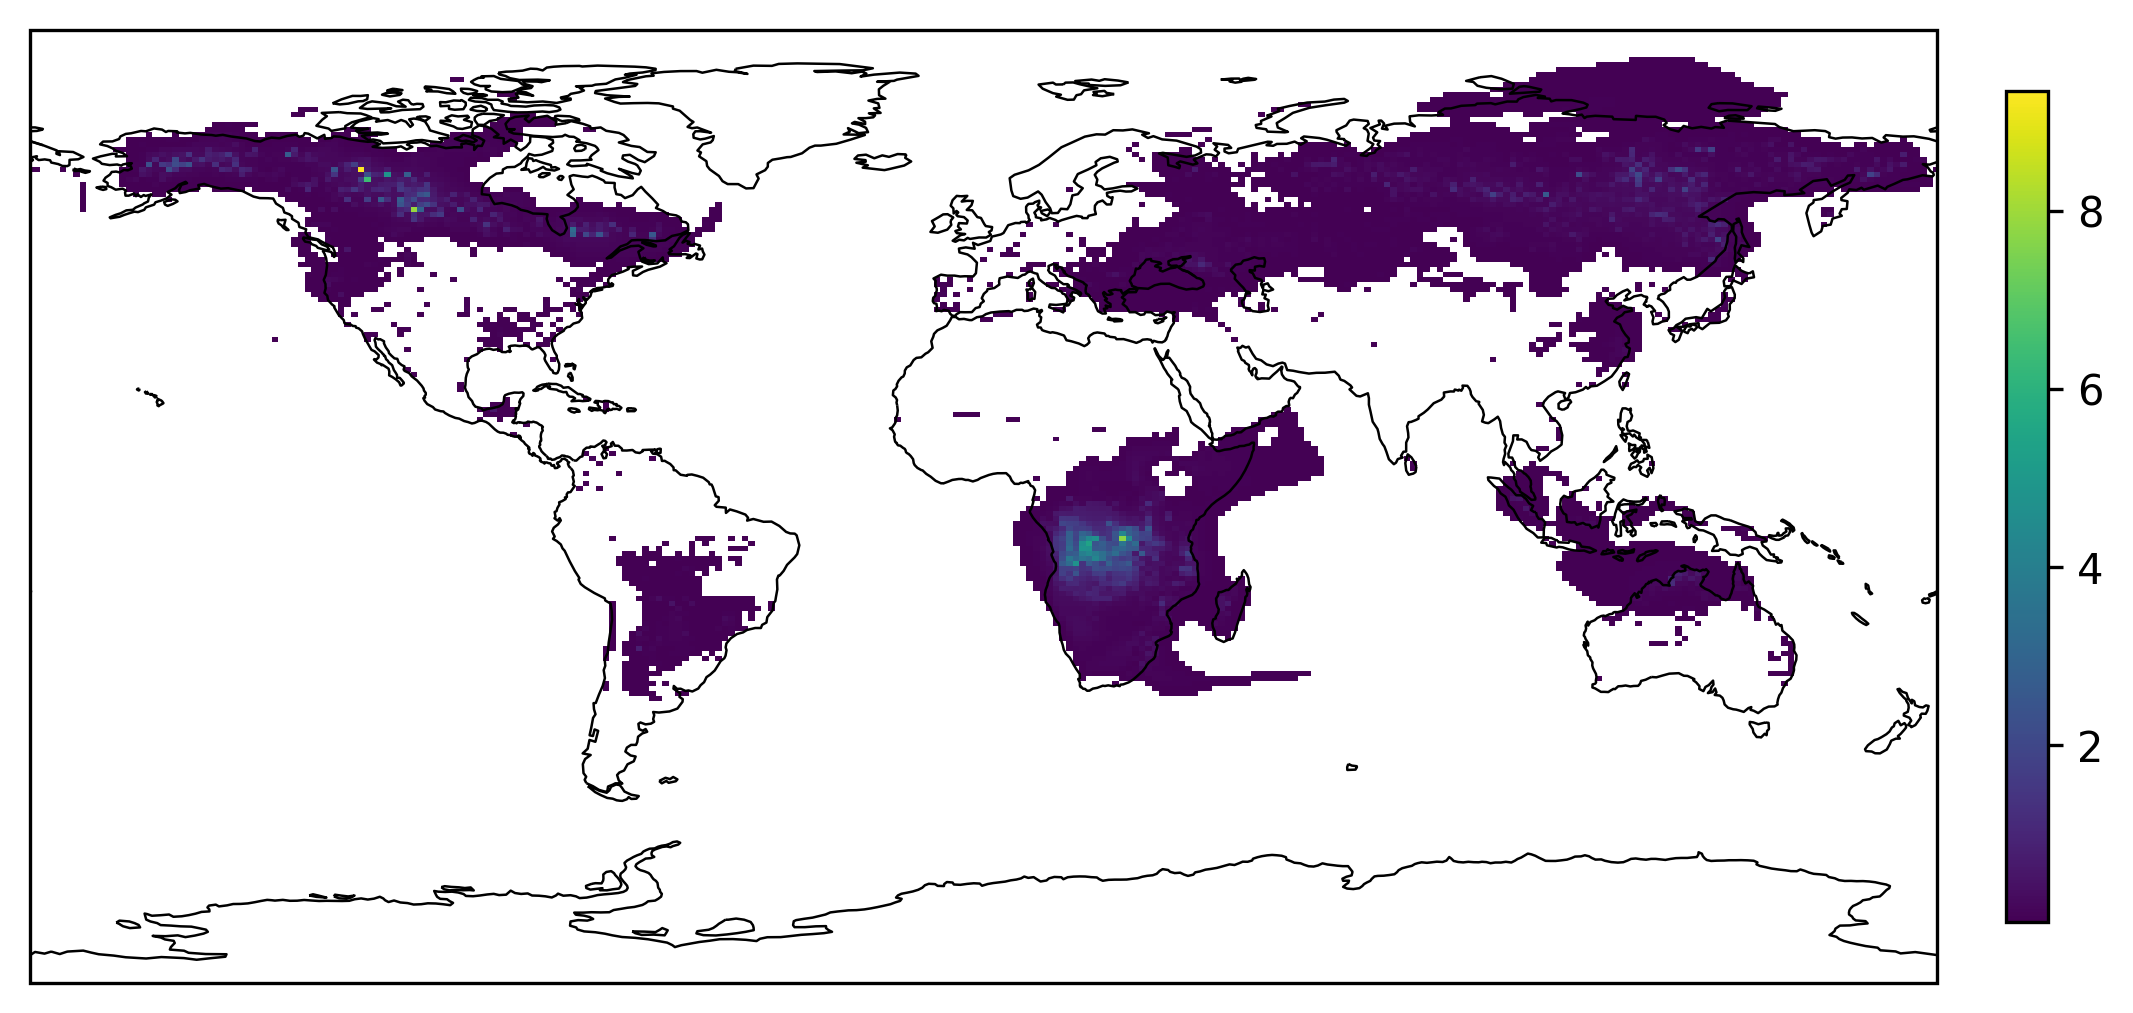

In [15]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib.cm as cm

# If blurry is (time, lat, lon), pick one month:
da2d = blurry*1e9

# Use a copy so you don't mutate the global viridis colormap
cmap = cm.get_cmap("viridis").copy()
cmap.set_under("white")

fig, ax = plt.subplots(
    figsize=(10, 4.5),
    dpi=300,
    subplot_kw={"projection": ccrs.PlateCarree()},
)

im = ax.pcolormesh(
    output_da0["lon"].values,
    output_da0["lat"].values,
    da2d,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    shading="auto",
    vmin=0.01,
)

ax.coastlines(linewidth=0.6)
ax.set_global()
plt.colorbar(im, ax=ax, shrink=0.8, pad=0.03)
plt.show()


In [12]:
da2d

array([[0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       ...,
       [1.4131981e-06, 1.3999279e-06, 2.8254378e-06, ..., 5.1112161e-06,
        3.8637140e-06, 2.7916749e-06],
       [8.8992210e-06, 2.5974501e-05, 7.5537158e-05, ..., 5.8931114e-06,
        6.2531008e-06, 8.7898807e-06],
       [3.1930293e-07, 1.3075719e-06, 1.3271860e-05, ..., 1.2649491e-07,
        1.7659653e-07, 2.4262795e-07]], shape=(192, 288), dtype=float32)

In [13]:
#ds = pipe.compute_and_save(save=False)